# Closed-Form Flow Matching：从解析速度场到 EFM

本 notebook 使用可控 toy 数据完整覆盖实验 A–J，研究论文 **On the Closed-Form of Flow Matching: Generalization Does Not Arise from Target Stochasticity** 的主要机制。重点不是复现 CIFAR-10 FID，而是逐项验证：

1. 经验分布最优速度场的闭式公式；
2. Target 随机性、环境维度和内在维度；
3. 精确经验流的记忆现象与神经网络近似；
4. EFM 估计器的无偏性、Target 方差和梯度方差；
5. 网络容量、Hybrid Flow 与泛化的关系。

所有代码都在本 notebook 中，结果保存到 `closed_form_fm_outputs/`。论文：[arXiv:2506.03719](https://arxiv.org/abs/2506.03719)。


## 1. 统一数学定义

固定训练集 $\mathcal D=\{x^{(i)}\}_{i=1}^N$，源分布为 $x_0\sim\mathcal N(0,I)$，线性条件路径为

$$x_t=(1-t)x_0+t x_1,\qquad u^{\mathrm{cond}}=x_1-x_0=\frac{x_1-x_t}{1-t}.$$

将数据分布替换成经验分布后，$p_t$ 是均值 $t x^{(i)}$、方差 $(1-t)^2I$ 的高斯混合。后验权重和最优经验速度为

$$
\lambda_i(x,t)=\operatorname{softmax}_i\!\left[-\frac{\|x-tx^{(i)}\|^2}{2(1-t)^2}\right],
$$

$$
\hat u^*(x,t)=\sum_i\lambda_i(x,t)\frac{x^{(i)}-x}{1-t}.
$$

当 $t\to1$ 时权重趋向最近训练样本，精确经验流会记忆有限训练集。神经网络只有在无法精确拟合该场时才可能平滑这种离散结构。


In [1]:
import copy, json, math, random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path("closed_form_fm_outputs"); OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": .2})

def seed_all(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

seed_all(42)
print("device:", DEVICE)
if DEVICE.type == "cuda": print("GPU:", torch.cuda.get_device_name(0))

@torch.no_grad()
def exact_velocity(x, t, dataset, return_weights=False):
    if not torch.is_tensor(t): t = torch.tensor(t, device=x.device, dtype=x.dtype)
    if t.ndim == 0: t = t.expand(len(x), 1)
    elif t.ndim == 1: t = t[:, None]
    one_minus = (1-t).clamp_min(1e-4)
    diff = x[:, None, :] - t[:, None, :] * dataset[None, :, :]
    logits = -diff.square().sum(-1) / (2 * one_minus.square())
    weights = torch.softmax(logits, dim=1)
    mean_x1 = weights @ dataset
    velocity = (mean_x1 - x) / one_minus
    return (velocity, weights) if return_weights else velocity

def sample_gmm(n, dim=2, modes=8, radius=4., std=.3):
    idx = torch.randint(modes, (n,), device=DEVICE)
    angles = 2*math.pi*idx.float()/modes
    x = torch.zeros(n, dim, device=DEVICE)
    x[:, 0] = radius*torch.cos(angles); x[:, 1] = radius*torch.sin(angles)
    return x + std*torch.randn_like(x)

@torch.no_grad()
def swd(x, y, n_proj=128):
    n = min(len(x), len(y))
    x, y = x[:n], y[:n]
    q = F.normalize(torch.randn(n_proj, x.shape[1], device=x.device), dim=1)
    return (torch.sort(x@q.T, dim=0).values-torch.sort(y@q.T, dim=0).values).abs().mean().item()


device: cuda
GPU: NVIDIA GeForce GTX 1050 Ti


## 2. 实验 A：闭式速度的正确性

混合分布的 score 为

$$\nabla_x\log p_t(x)=-\frac{x-t\sum_i\lambda_i x^{(i)}}{(1-t)^2}.$$

因此在 $t>0$ 时还有

$$\hat u^*(x,t)=\frac{x+(1-t)\nabla_x\log p_t(x)}{t}.$$

下面比较直接后验平均、score 公式和从后验采样条件速度的 Monte Carlo 均值。


{'score_relation_max_abs': 9.5367431640625e-07, 'posterior_mc_rmse': 0.026505324989557266}


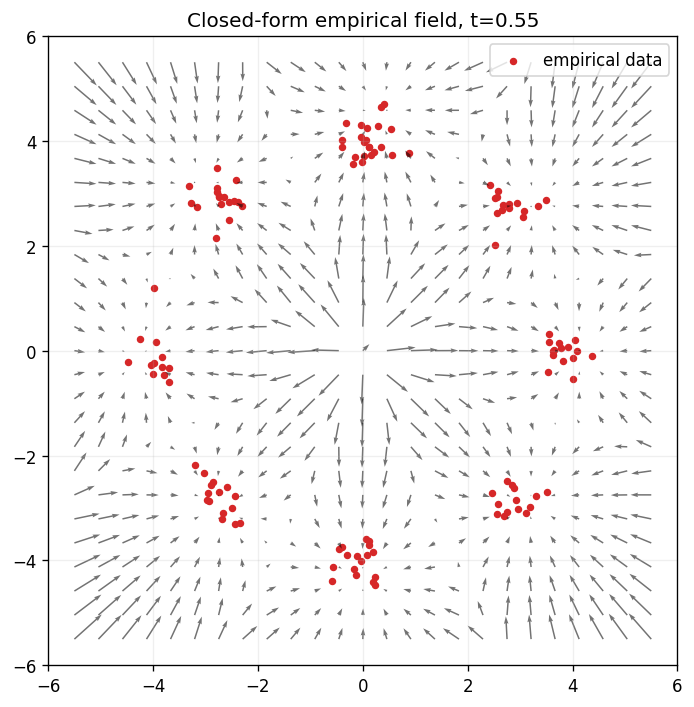

In [2]:
seed_all(1)
toy_data = sample_gmm(128)
B, t_value = 256, 0.55
x1 = toy_data[torch.randint(len(toy_data), (B,), device=DEVICE)]
x0 = torch.randn_like(x1); xt = (1-t_value)*x0+t_value*x1
v_closed, w = exact_velocity(xt, t_value, toy_data, True)
posterior_mean = w @ toy_data
score = -(xt-t_value*posterior_mean)/(1-t_value)**2
v_score = (xt+(1-t_value)*score)/t_value

draws = torch.multinomial(w, 2048, replacement=True)
posterior_samples = toy_data[draws]
v_mc = ((posterior_samples-xt[:, None, :])/(1-t_value)).mean(1)
A_metrics = {
    "score_relation_max_abs": (v_closed-v_score).abs().max().item(),
    "posterior_mc_rmse": (v_closed-v_mc).square().mean().sqrt().item(),
}
print(A_metrics)

fig, ax = plt.subplots(figsize=(6,6))
g = torch.linspace(-5.5,5.5,25,device=DEVICE)
gx,gy=torch.meshgrid(g,g,indexing="xy"); grid=torch.stack([gx.ravel(),gy.ravel()],1)
vg=exact_velocity(grid,t_value,toy_data).cpu(); grid=grid.cpu(); d=toy_data.cpu()
ax.scatter(d[:,0],d[:,1],s=12,c="tab:red",label="empirical data")
ax.quiver(grid[:,0],grid[:,1],vg[:,0],vg[:,1],alpha=.55)
ax.set(title=f"Closed-form empirical field, t={t_value}",aspect="equal",xlim=(-6,6),ylim=(-6,6)); ax.legend()
fig.tight_layout(); fig.savefig(OUT/"01_closed_form_field.png",bbox_inches="tight"); plt.show()


## 3. 实验 B：Target 随机性与维度

对每个前向样本比较条件 Target $u^{\mathrm{cond}}$ 和闭式场 $\hat u^*$。记录余弦相似度超过 0.9 的比例、后验归一化熵和后验条件速度方差。若后验在高维中更快集中，条件 Target 会更接近闭式 Target。


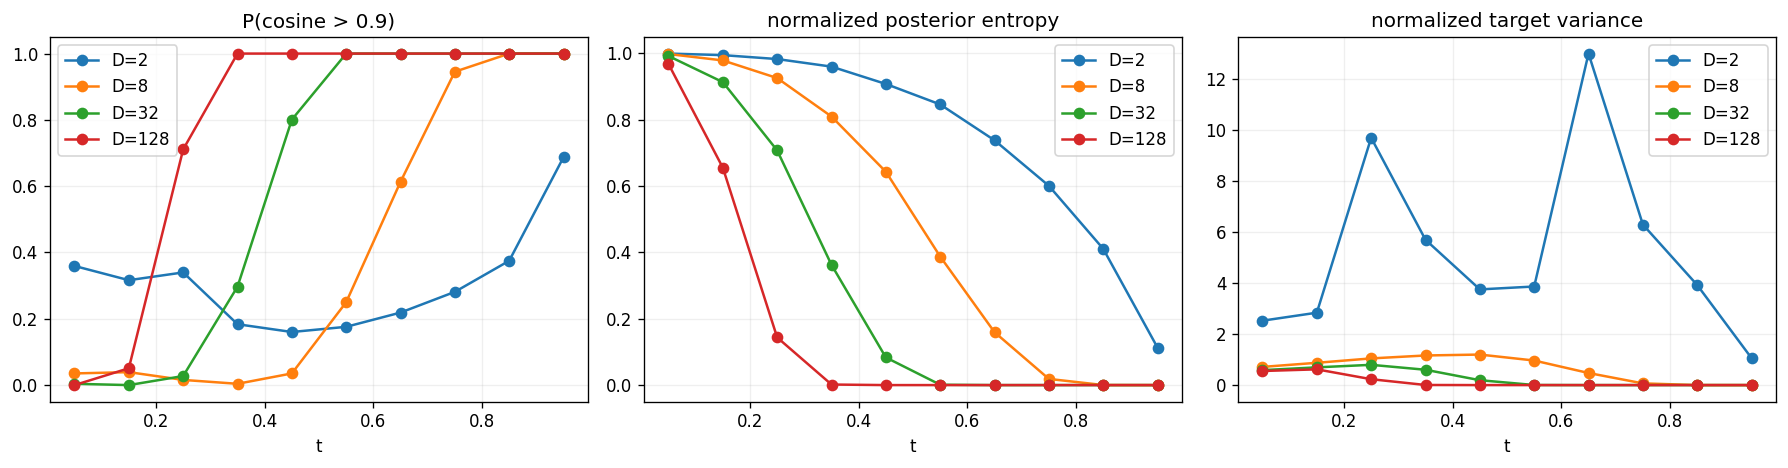

In [3]:
@torch.no_grad()
def dimension_statistics(dim, times, n_data=256, batch=256, intrinsic=None, seed=0):
    seed_all(seed)
    if intrinsic is None:
        data=torch.randn(n_data,dim,device=DEVICE)
    else:
        q,_=torch.linalg.qr(torch.randn(dim,intrinsic,device=DEVICE),mode="reduced")
        data=torch.randn(n_data,intrinsic,device=DEVICE)@q.T
    rows=[]
    for tv in times:
        idx=torch.randint(n_data,(batch,),device=DEVICE); x1=data[idx]; x0=torch.randn_like(x1)
        xt=(1-tv)*x0+tv*x1; cond=x1-x0
        v,w=exact_velocity(xt,tv,data,True)
        cos=F.cosine_similarity(cond,v,dim=1)
        entropy=-(w*(w.clamp_min(1e-30).log())).sum(1)/math.log(n_data)
        candidates=(data[None,:,:]-xt[:,None,:])/(1-tv)
        post_var=(w[:,:,None]*(candidates-v[:,None,:]).square()).sum((1,2))/dim
        cond_energy=cond.square().sum(1)/dim
        rows.append([float(tv),(cos>.9).float().mean().item(),entropy.mean().item(),
                     (post_var/(cond_energy+1e-8)).mean().item()])
    return np.asarray(rows)

times=np.linspace(.05,.95,10); dims=[2,8,32,128]
B_results={d:dimension_statistics(d,times,seed=d) for d in dims}
fig,axes=plt.subplots(1,3,figsize=(15,4))
for d in dims:
    r=B_results[d]
    for j in range(3): axes[j].plot(r[:,0],r[:,j+1],"o-",label=f"D={d}")
for ax,title in zip(axes,["P(cosine > 0.9)","normalized posterior entropy","normalized target variance"]):
    ax.set(xlabel="t",title=title); ax.legend()
fig.tight_layout(); fig.savefig(OUT/"02_dimension_target_randomness.png",bbox_inches="tight"); plt.show()


## 4. 实验 C：精确经验速度场会记忆训练集

用 RK2 中点法直接积分闭式经验场。随着终止时间接近 1，样本应被吸引到某个训练点。评价生成样本到训练集最近邻的距离，并与独立测试样本作比较。


{'generated_to_train_nn': 0.012386352755129337, 'test_to_train_nn': 0.17973968386650085, 'generated_vs_true_swd': 0.26415520906448364}


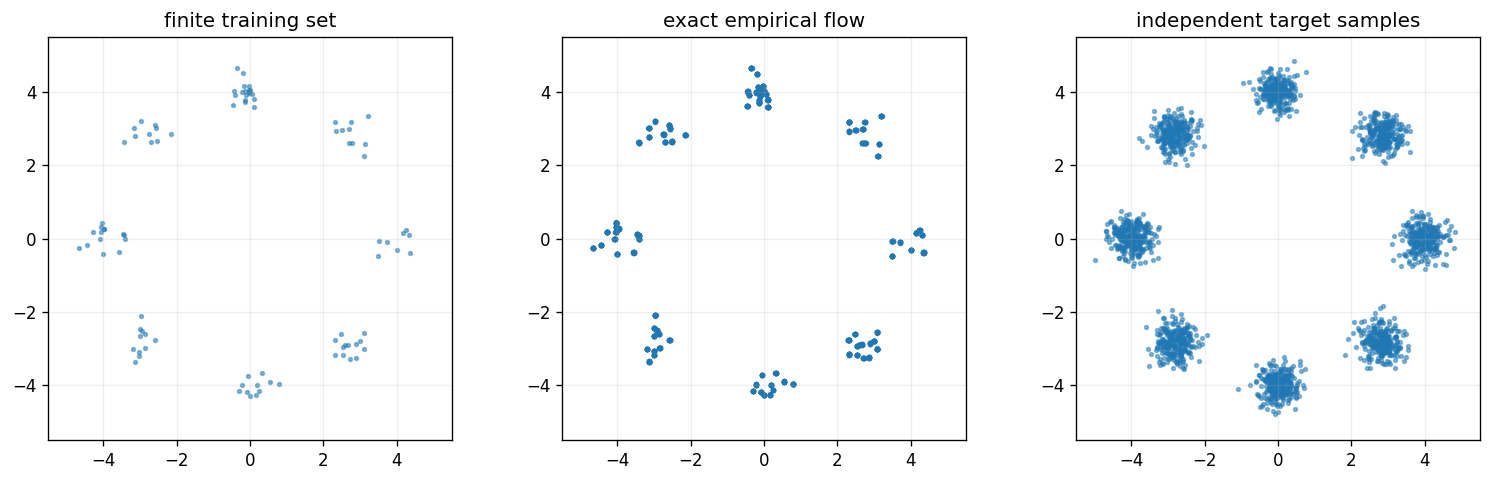

In [4]:
@torch.no_grad()
def integrate_field(x0, field, steps=120, t_end=.995, switch=None):
    x=x0.clone(); dt=t_end/steps
    for k in range(steps):
        t=k*dt
        f=field if switch is None else switch(t)
        tm=torch.full((len(x),1),t,device=DEVICE)
        v1=f(x,tm); xm=x+.5*dt*v1
        v2=f(xm,tm+.5*dt); x=x+dt*v2
    return x

seed_all(3)
train_data=sample_gmm(96); test_data=sample_gmm(2048); source=torch.randn(2048,2,device=DEVICE)
closed=lambda x,t: exact_velocity(x,t,train_data)
exact_samples=integrate_field(source,closed,steps=160,t_end=.997)
nn_exact=torch.cdist(exact_samples,train_data).min(1).values
nn_test=torch.cdist(test_data,train_data).min(1).values
C_metrics={"generated_to_train_nn":nn_exact.mean().item(),"test_to_train_nn":nn_test.mean().item(),
           "generated_vs_true_swd":swd(exact_samples,test_data)}
print(C_metrics)
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,q,title in zip(axes,[train_data,exact_samples,test_data],["finite training set","exact empirical flow","independent target samples"]):
    z=q.cpu(); ax.scatter(z[:,0],z[:,1],s=5,alpha=.5); ax.set(title=title,aspect="equal",xlim=(-5.5,5.5),ylim=(-5.5,5.5))
fig.tight_layout(); fig.savefig(OUT/"03_exact_flow_memorization.png",bbox_inches="tight"); plt.show()


### 4.1 闭式速度场的 ODE 生成过程

“闭式解”指的是速度向量场 $\hat u^*(x,t)$ 可以直接计算，并不表示每条非线性 ODE 轨迹都具有简单的解析表达式。下面使用 RK2 中点法积分

$$\frac{d x_t}{dt}=\hat u^*(x_t,t),$$

记录多个时间截面的边际样本和若干粒子轨迹。由于速度场在 $t=1$ 具有 $1/(1-t)$ 奇异项，数值积分终止在 $t=0.997$。


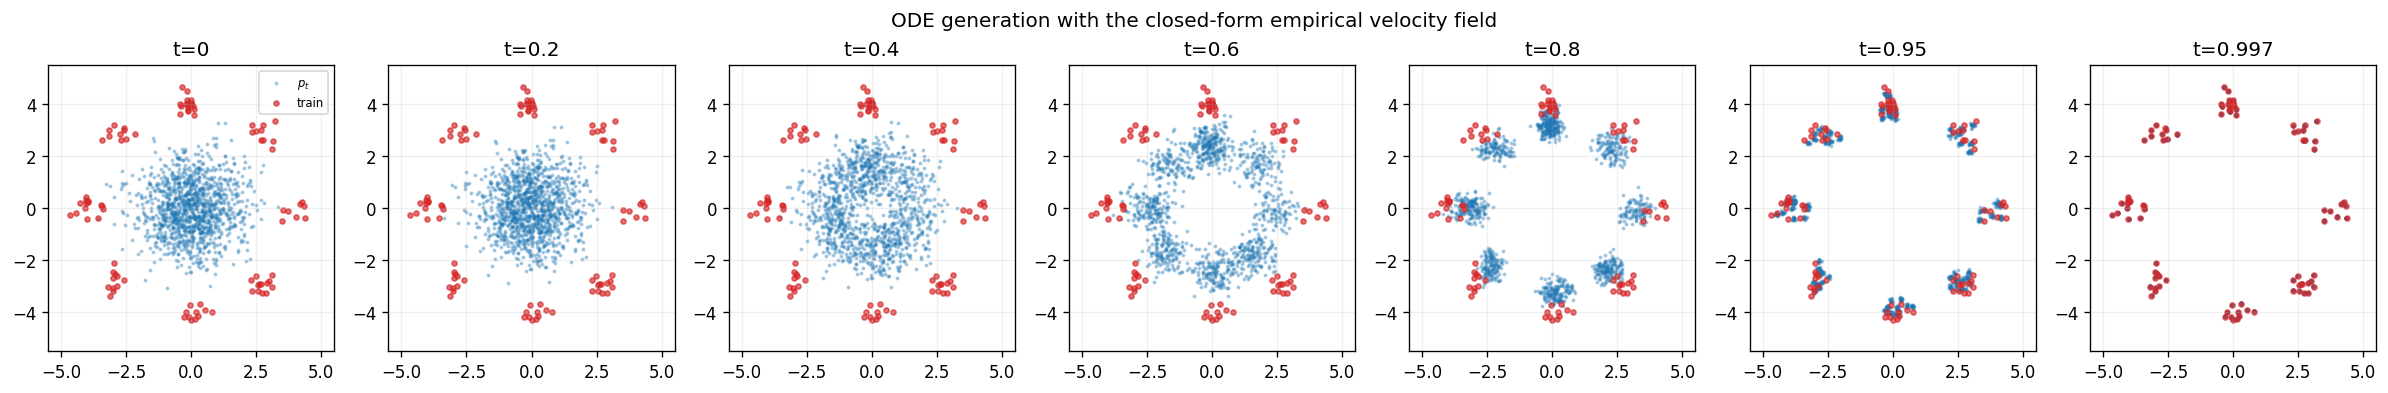

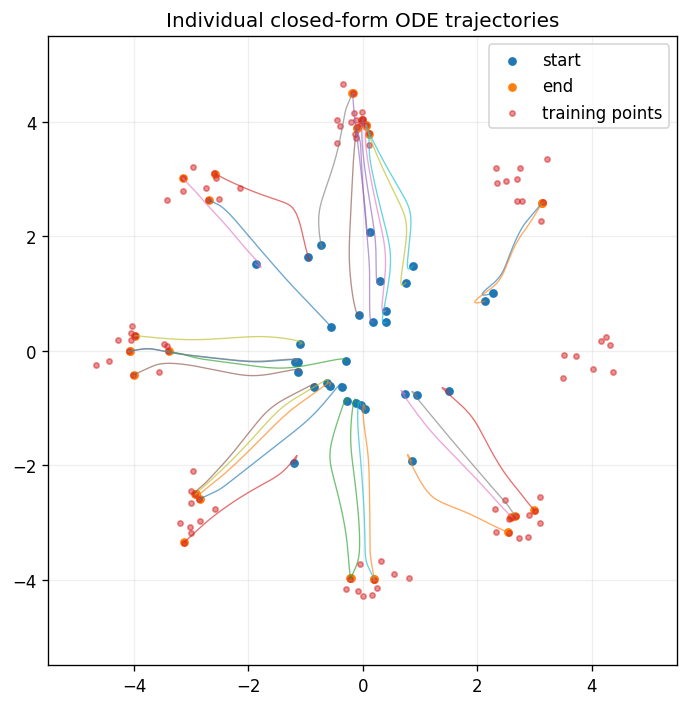

In [5]:
@torch.no_grad()
def integrate_closed_form_snapshots(x0, dataset, steps=180, t_end=.997,
                                    record_times=(0,.2,.4,.6,.8,.95,.997)):
    x=x0.clone(); dt=t_end/steps
    snapshots={0.0:x.clone()}; trajectory=[x.clone()]
    targets=list(record_times[1:]); next_id=0
    for k in range(steps):
        t=k*dt
        tt=torch.full((len(x),1),t,device=x.device)
        v1=exact_velocity(x,tt,dataset)
        x_mid=x+.5*dt*v1
        v2=exact_velocity(x_mid,tt+.5*dt,dataset)
        x=x+dt*v2
        trajectory.append(x.clone())
        current=(k+1)*dt
        while next_id<len(targets) and current>=targets[next_id]-dt/2:
            snapshots[targets[next_id]]=x.clone(); next_id+=1
    return snapshots,torch.stack(trajectory)

seed_all(31)
path_source=torch.randn(1200,2,device=DEVICE)
record_times=(0,.2,.4,.6,.8,.95,.997)
snapshots,all_trajectory=integrate_closed_form_snapshots(path_source,train_data,record_times=record_times)

fig,axes=plt.subplots(1,len(record_times),figsize=(20,3.1))
train_cpu=train_data.cpu()
for ax,tv in zip(axes,record_times):
    q=snapshots[tv].cpu()
    ax.scatter(q[:,0],q[:,1],s=2,alpha=.3,label="$p_t$")
    ax.scatter(train_cpu[:,0],train_cpu[:,1],s=9,c="tab:red",alpha=.65,label="train")
    ax.set(title=f"t={tv:g}",xlim=(-5.5,5.5),ylim=(-5.5,5.5),aspect="equal")
axes[0].legend(fontsize=7)
fig.suptitle("ODE generation with the closed-form empirical velocity field")
fig.tight_layout();fig.savefig(OUT/"03b_closed_form_ode_snapshots.png",bbox_inches="tight");plt.show()

fig,ax=plt.subplots(figsize=(6,6))
traj=all_trajectory[:, :32].cpu()
for i in range(traj.shape[1]):ax.plot(traj[:,i,0],traj[:,i,1],lw=.8,alpha=.65)
ax.scatter(traj[0,:,0],traj[0,:,1],s=18,c="tab:blue",label="start")
ax.scatter(traj[-1,:,0],traj[-1,:,1],s=18,c="tab:orange",label="end")
ax.scatter(train_cpu[:,0],train_cpu[:,1],s=10,c="tab:red",alpha=.5,label="training points")
ax.set(title="Individual closed-form ODE trajectories",xlim=(-5.5,5.5),ylim=(-5.5,5.5),aspect="equal")
ax.legend();fig.tight_layout();fig.savefig(OUT/"03c_closed_form_ode_trajectories.png",bbox_inches="tight");plt.show()


## 5. 实验 F：EFM 无偏性与方差

EFM 候选集必须包含 $b^{(1)}=x_1$，其中该 $x_1$ 与 $x_t$ 来自同一前向样本；其余 $M-1$ 个候选从经验分布独立采样。固定 $(x,t)$ 后，这等价于从精确后验抽取第一个候选，再从先验抽取其余候选。

我们同时加入两个错误对照：所有候选均匀采样，以及候选速度直接算术平均。


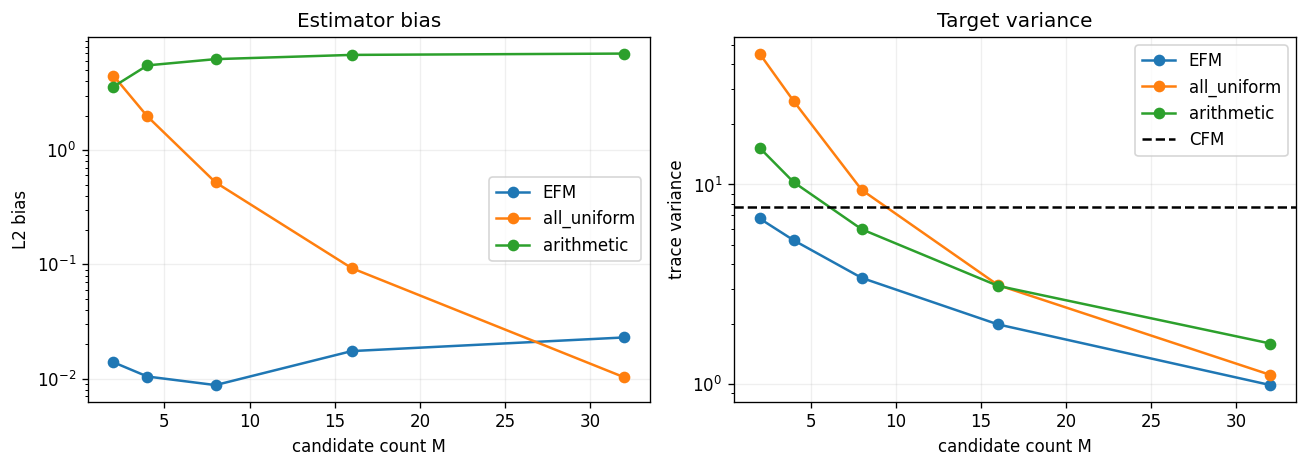

{
  "CFM": {
    "bias": 0.04219866544008255,
    "variance": 7.686306476593018
  },
  "EFM_M2": {
    "bias": 0.013951119035482407,
    "variance": 6.756483554840088
  },
  "all_uniform_M2": {
    "bias": 4.485291004180908,
    "variance": 45.17626953125
  },
  "arithmetic_M2": {
    "bias": 3.5840096473693848,
    "variance": 15.264432907104492
  },
  "EFM_M4": {
    "bias": 0.010459978133440018,
    "variance": 5.257132530212402
  },
  "all_uniform_M4": {
    "bias": 1.9696930646896362,
    "variance": 26.130325317382812
  },
  "arithmetic_M4": {
    "bias": 5.506869792938232,
    "variance": 10.26618480682373
  },
  "EFM_M8": {
    "bias": 0.008802449330687523,
    "variance": 3.4066848754882812
  },
  "all_uniform_M8": {
    "bias": 0.5219806432723999,
    "variance": 9.381817817687988
  },
  "arithmetic_M8": {
    "bias": 6.2448954582214355,
    "variance": 5.964540481567383
  },
  "EFM_M16": {
    "bias": 0.017461149021983147,
    "variance": 1.9939031600952148
  },
  "all_unifo

In [6]:
@torch.no_grad()
def efm_mc_study(dataset, x, t=.45, reps=3000, Ms=(2,4,8,16,32)):
    x=x.view(1,-1); exact,w=exact_velocity(x,t,dataset,True); exact=exact[0]
    n,D=len(dataset),dataset.shape[1]; out={}
    posterior=torch.multinomial(w[0],reps,replacement=True)
    cfm=(dataset[posterior]-x)/(1-t)
    out["CFM"]={"bias":(cfm.mean(0)-exact).norm().item(),"variance":cfm.var(0,unbiased=False).sum().item()}
    for M in Ms:
        rest=torch.randint(n,(reps,M-1),device=DEVICE)
        correct=torch.cat([posterior[:,None],rest],1)
        uniform=torch.randint(n,(reps,M),device=DEVICE)
        def estimate(indices,weighted=True):
            cand=dataset[indices]
            vel=(cand-x[None,:,:])/(1-t)
            if not weighted:return vel.mean(1)
            logits=-(x[None,:,:]-t*cand).square().sum(-1)/(2*(1-t)**2)
            return (torch.softmax(logits,1)[:,:,None]*vel).sum(1)
        for name,ind,weighted in [("EFM",correct,True),("all_uniform",uniform,True),("arithmetic",correct,False)]:
            est=estimate(ind,weighted); out[f"{name}_M{M}"]={
                "bias":(est.mean(0)-exact).norm().item(),
                "variance":est.var(0,unbiased=False).sum().item()}
    return out

seed_all(5); anchor=train_data[0]; x_probe=.55*torch.randn_like(anchor)+.45*anchor
F_results=efm_mc_study(train_data,x_probe)
Ms=[2,4,8,16,32]
fig,axes=plt.subplots(1,2,figsize=(11,4))
for name in ["EFM","all_uniform","arithmetic"]:
    axes[0].plot(Ms,[F_results[f"{name}_M{m}"]["bias"] for m in Ms],"o-",label=name)
    axes[1].plot(Ms,[F_results[f"{name}_M{m}"]["variance"] for m in Ms],"o-",label=name)
axes[1].axhline(F_results["CFM"]["variance"],ls="--",c="k",label="CFM")
axes[0].set(title="Estimator bias",xlabel="candidate count M",ylabel="L2 bias",yscale="log")
axes[1].set(title="Target variance",xlabel="candidate count M",ylabel="trace variance",yscale="log")
for ax in axes: ax.legend()
fig.tight_layout(); fig.savefig(OUT/"04_efm_unbiased_variance.png",bbox_inches="tight"); plt.show()
print(json.dumps(F_results,indent=2))


## 6. 实验 D/G：训练 CFM 与 EFM 网络

CFM 使用随机条件 Target；EFM 使用包含真实 $x_1$ 的候选集加权平均。两者使用相同网络、batch、优化器和训练步数。比较训练曲线、对精确经验场的拟合误差、生成 SWD 与训练集最近邻距离。


Training CFM...


cfm width=128 step=1000 loss=3.1771


cfm width=128 step=2000 loss=3.6770


cfm width=128 step=3000 loss=4.0055
Training EFM...


efm width=128 step=1000 loss=0.5426


efm width=128 step=2000 loss=0.5959


efm width=128 step=3000 loss=0.5318


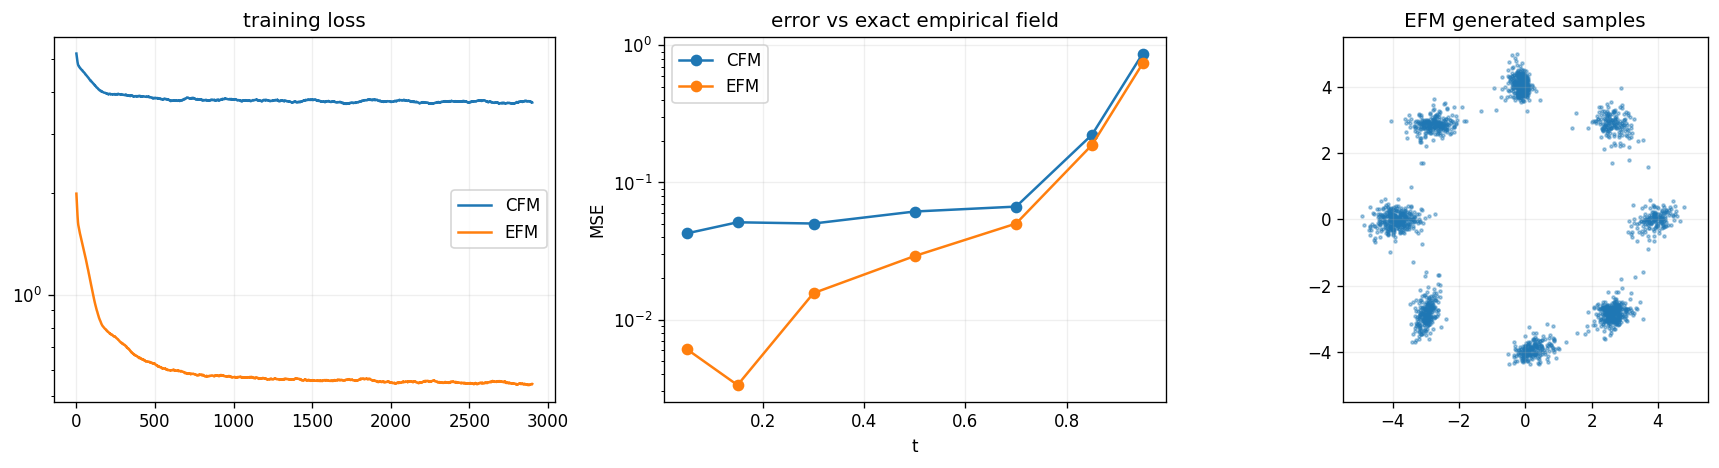

{
  "CFM": {
    "times": [
      0.05000000074505806,
      0.15000000596046448,
      0.30000001192092896,
      0.5,
      0.699999988079071,
      0.8500000238418579,
      0.949999988079071
    ],
    "field_mse": [
      0.04253050684928894,
      0.05122130364179611,
      0.050179313868284225,
      0.061396460980176926,
      0.0666687935590744,
      0.22321629524230957,
      0.8708879351615906
    ],
    "swd": 0.19203805923461914,
    "nn_train": 0.15656733512878418
  },
  "EFM": {
    "times": [
      0.05000000074505806,
      0.15000000596046448,
      0.30000001192092896,
      0.5,
      0.699999988079071,
      0.8500000238418579,
      0.949999988079071
    ],
    "field_mse": [
      0.00607775803655386,
      0.003327375277876854,
      0.015593679621815681,
      0.0290985144674778,
      0.0501386821269989,
      0.18813106417655945,
      0.7385395765304565
    ],
    "swd": 0.2920973300933838,
    "nn_train": 0.1526615172624588
  }
}


In [7]:
class VelocityMLP(nn.Module):
    def __init__(self,dim=2,width=128,depth=3):
        super().__init__(); self.dim=dim
        self.register_buffer("freq",2.**torch.arange(6))
        layers=[]; n=dim+13
        for _ in range(depth): layers += [nn.Linear(n,width),nn.SiLU()]; n=width
        layers += [nn.Linear(n,dim)]; self.net=nn.Sequential(*layers)
    def forward(self,x,t):
        if t.ndim==1:t=t[:,None]
        a=2*math.pi*t*self.freq
        return self.net(torch.cat([x,t,torch.sin(a),torch.cos(a)],1))

def make_training_batch(dataset,batch,kind="cfm",M=16):
    idx=torch.randint(len(dataset),(batch,),device=DEVICE); x1=dataset[idx]
    x0=torch.randn_like(x1); t=torch.rand(batch,1,device=DEVICE)*.98
    xt=(1-t)*x0+t*x1
    if kind=="cfm": target=x1-x0
    else:
        other=torch.randint(len(dataset),(batch,M-1),device=DEVICE)
        cand=torch.cat([x1[:,None,:],dataset[other]],1)
        logits=-(xt[:,None,:]-t[:,None,:]*cand).square().sum(-1)/(2*(1-t).square())
        target=(torch.softmax(logits,1)[:,:,None]*(cand-xt[:,None,:])/(1-t[:,None,:])).sum(1)
    return xt,t,target.detach()

def train_velocity(dataset,kind="cfm",width=128,steps=3000,batch=512,M=16,seed=10):
    seed_all(seed); model=VelocityMLP(dataset.shape[1],width).to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=2e-3,weight_decay=1e-4); hist=[]
    for step in range(1,steps+1):
        x,t,y=make_training_batch(dataset,batch,kind,M); loss=(model(x,t)-y).square().mean()
        opt.zero_grad(set_to_none=True); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),5); opt.step()
        hist.append(loss.item())
        if step%1000==0: print(f"{kind} width={width} step={step} loss={loss.item():.4f}")
    return model.eval(),hist

print("Training CFM..."); cfm_model,cfm_hist=train_velocity(train_data,"cfm")
print("Training EFM..."); efm_model,efm_hist=train_velocity(train_data,"efm")

@torch.no_grad()
def network_diagnostics(model,dataset,test_target):
    ts=torch.tensor([.05,.15,.3,.5,.7,.85,.95],device=DEVICE); mse=[]
    for tv in ts:
        idx=torch.randint(len(dataset),(512,),device=DEVICE); x1=dataset[idx]; x0=torch.randn_like(x1)
        x=(1-tv)*x0+tv*x1; tt=torch.full((len(x),1),float(tv),device=DEVICE)
        mse.append((model(x,tt)-exact_velocity(x,tt,dataset)).square().mean().item())
    source=torch.randn(2048,dataset.shape[1],device=DEVICE)
    gen=integrate_field(source,lambda x,t:model(x,t),steps=80,t_end=.995)
    return {"times":ts.cpu().tolist(),"field_mse":mse,"swd":swd(gen,test_target),
            "nn_train":torch.cdist(gen,dataset).min(1).values.mean().item()},gen

D_results={}; D_results["CFM"],cfm_samples=network_diagnostics(cfm_model,train_data,test_data)
D_results["EFM"],efm_samples=network_diagnostics(efm_model,train_data,test_data)
def smooth(a,w=100): return np.convolve(a,np.ones(w)/w,mode="valid")
fig,axes=plt.subplots(1,3,figsize=(15,4))
axes[0].plot(smooth(cfm_hist),label="CFM"); axes[0].plot(smooth(efm_hist),label="EFM"); axes[0].set(title="training loss",yscale="log"); axes[0].legend()
for name in ["CFM","EFM"]: axes[1].plot(D_results[name]["times"],D_results[name]["field_mse"],"o-",label=name)
axes[1].set(title="error vs exact empirical field",xlabel="t",ylabel="MSE",yscale="log"); axes[1].legend()
for ax,q,title in zip(axes[2:],[efm_samples],["EFM generated samples"]):
    z=q.cpu(); ax.scatter(z[:,0],z[:,1],s=3,alpha=.4); ax.set(title=title,aspect="equal",xlim=(-5.5,5.5),ylim=(-5.5,5.5))
fig.tight_layout(); fig.savefig(OUT/"05_cfm_efm_training.png",bbox_inches="tight"); plt.show()
print(json.dumps(D_results,indent=2))


## 7. 实验 E：Hybrid Flow 的关键时间段

分别测试两种切换方向：

- **Exact → Network**：早期使用精确经验场，晚期使用网络；
- **Network → Exact**：早期使用网络，晚期使用精确经验场。

若早期网络近似是泛化的关键来源，两种切换方向会产生不同的记忆程度。


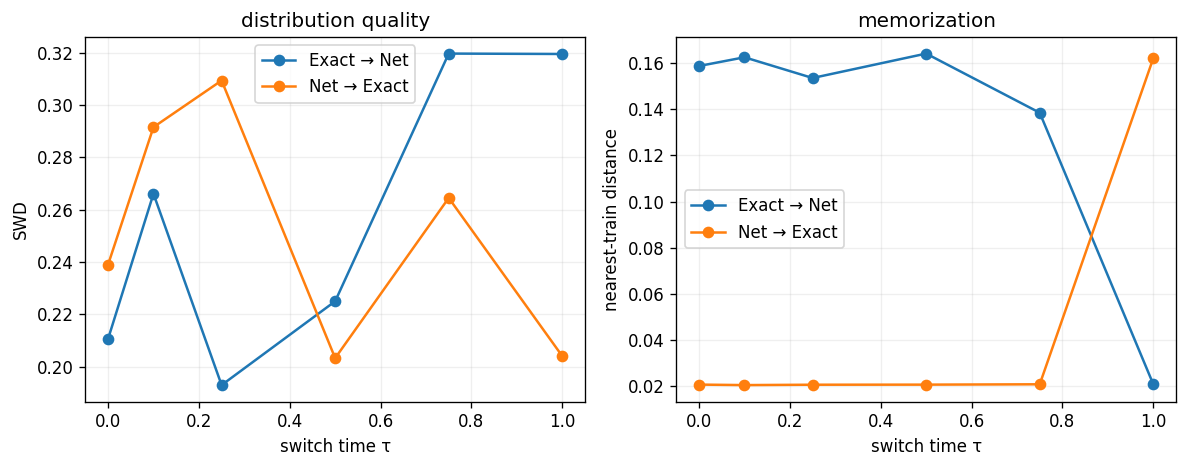

In [8]:
@torch.no_grad()
def hybrid_generate(tau,exact_first=True,n=1024):
    src=torch.randn(n,2,device=DEVICE)
    exact=lambda x,t:exact_velocity(x,t,train_data); neural=lambda x,t:cfm_model(x,t)
    switch=(lambda t: exact if t<tau else neural) if exact_first else (lambda t: neural if t<tau else exact)
    return integrate_field(src,None,steps=100,t_end=.995,switch=switch)

taus=[0,.1,.25,.5,.75,1.0]; E_results={"exact_then_net":{},"net_then_exact":{}}
for tau in taus:
    for key,direction in [("exact_then_net",True),("net_then_exact",False)]:
        g=hybrid_generate(tau,direction); E_results[key][str(tau)]={
            "swd":swd(g,test_data),"nn_train":torch.cdist(g,train_data).min(1).values.mean().item()}
fig,axes=plt.subplots(1,2,figsize=(10,4))
for key,label in [("exact_then_net","Exact → Net"),("net_then_exact","Net → Exact")]:
    axes[0].plot(taus,[E_results[key][str(t)]["swd"] for t in taus],"o-",label=label)
    axes[1].plot(taus,[E_results[key][str(t)]["nn_train"] for t in taus],"o-",label=label)
axes[0].set(title="distribution quality",xlabel="switch time τ",ylabel="SWD")
axes[1].set(title="memorization",xlabel="switch time τ",ylabel="nearest-train distance")
for ax in axes:ax.legend()
fig.tight_layout(); fig.savefig(OUT/"06_hybrid_flow.png",bbox_inches="tight"); plt.show()


## 8. 实验 H：环境维度与内在维度

把 $r$ 维潜变量线性嵌入到 $D$ 维空间。固定 $r$ 改变 $D$ 时，候选之间的相对距离主要由数据子空间决定；固定 $D$ 改变 $r$ 才会显著改变后验集中速度。因此需要区分环境维度和内在维度。


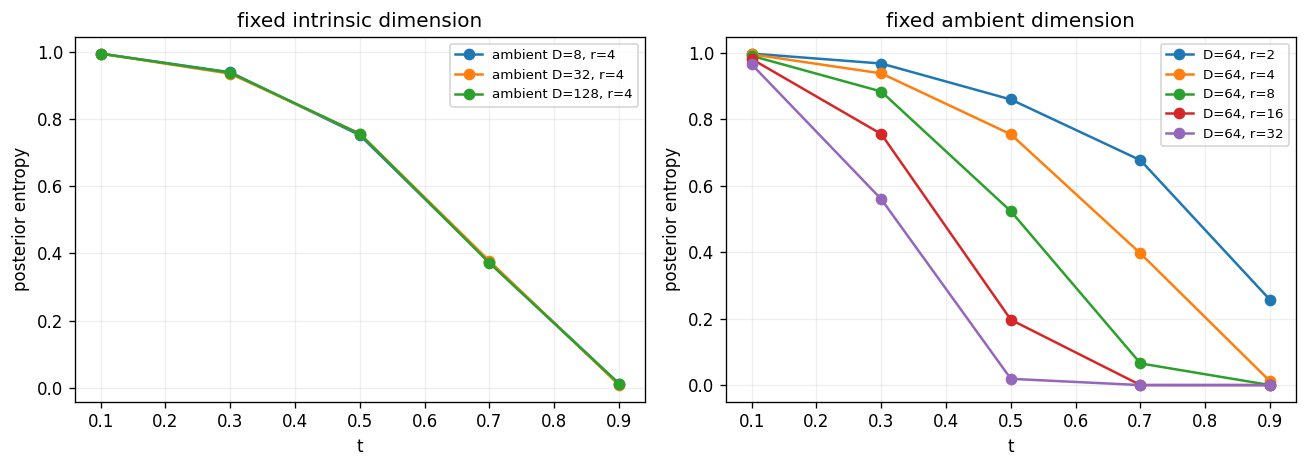

In [9]:
H_times=np.array([.1,.3,.5,.7,.9]); H_results={"ambient":{},"intrinsic":{}}
for D in [8,32,128]: H_results["ambient"][str(D)]=dimension_statistics(D,H_times,intrinsic=4,seed=7)
for r in [2,4,8,16,32]: H_results["intrinsic"][str(r)]=dimension_statistics(64,H_times,intrinsic=r,seed=8+r)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for D,v in H_results["ambient"].items():axes[0].plot(v[:,0],v[:,2],"o-",label=f"ambient D={D}, r=4")
for r,v in H_results["intrinsic"].items():axes[1].plot(v[:,0],v[:,2],"o-",label=f"D=64, r={r}")
for ax,title in zip(axes,["fixed intrinsic dimension","fixed ambient dimension"]):ax.set(title=title,xlabel="t",ylabel="posterior entropy");ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/"07_ambient_intrinsic_dimension.png",bbox_inches="tight");plt.show()


## 9. 实验 I：网络容量与记忆

在相同 CFM 训练预算下比较窄网络、基准网络和宽网络。容量越大通常越接近精确经验场，也可能更靠近有限训练点；这不是单调定理，需要同时观察场误差、SWD 和最近训练样本距离。


Training capacity width=32...


cfm width=32 step=1000 loss=3.3715


cfm width=32 step=2000 loss=3.8621


cfm width=32 step=3000 loss=3.3599
Training capacity width=256...


cfm width=256 step=1000 loss=4.0658


cfm width=256 step=2000 loss=3.4232


cfm width=256 step=3000 loss=3.7200


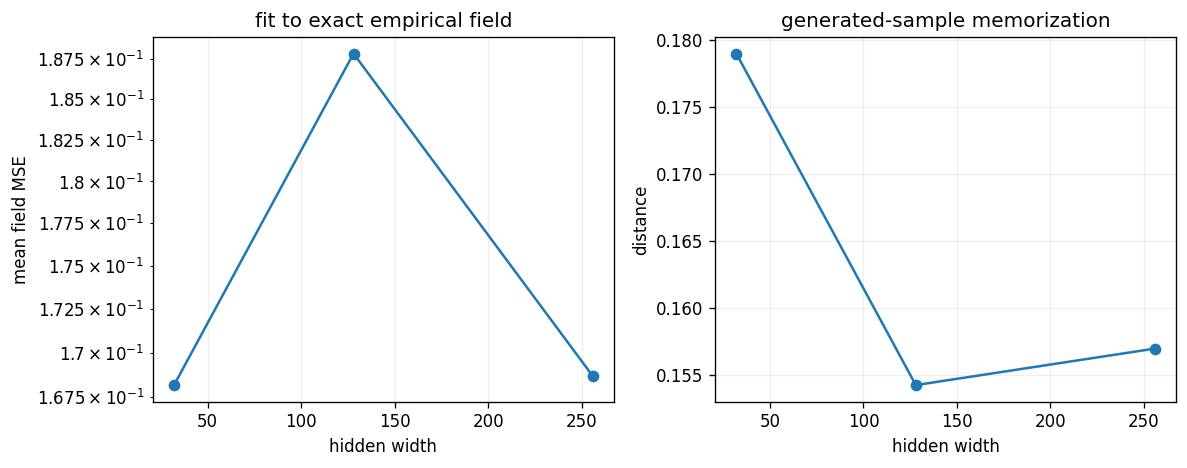

In [10]:
capacity_models={128:cfm_model}; capacity_hist={128:cfm_hist}
for width in [32,256]:
    print(f"Training capacity width={width}...")
    capacity_models[width],capacity_hist[width]=train_velocity(train_data,"cfm",width=width,steps=3000,seed=20+width)
I_results={}; cap_samples={}
for width,model in capacity_models.items():I_results[str(width)],cap_samples[width]=network_diagnostics(model,train_data,test_data)
fig,axes=plt.subplots(1,2,figsize=(10,4)); widths=[32,128,256]
axes[0].plot(widths,[np.mean(I_results[str(w)]["field_mse"]) for w in widths],"o-")
axes[0].set(title="fit to exact empirical field",xlabel="hidden width",ylabel="mean field MSE",yscale="log")
axes[1].plot(widths,[I_results[str(w)]["nn_train"] for w in widths],"o-",label="nearest train")
axes[1].set(title="generated-sample memorization",xlabel="hidden width",ylabel="distance")
fig.tight_layout();fig.savefig(OUT/"08_capacity_memorization.png",bbox_inches="tight");plt.show()


## 10. 实验 J：Target 方差是否传递为梯度方差

在同一个已训练网络参数点上，重复抽取 CFM 或 EFM batch，计算 batch 梯度。用

$$\mathbb E\|g-\mathbb E g\|^2$$

估计梯度协方差的迹，从而区分“Target 方差降低”和“优化器实际看到的梯度方差降低”。


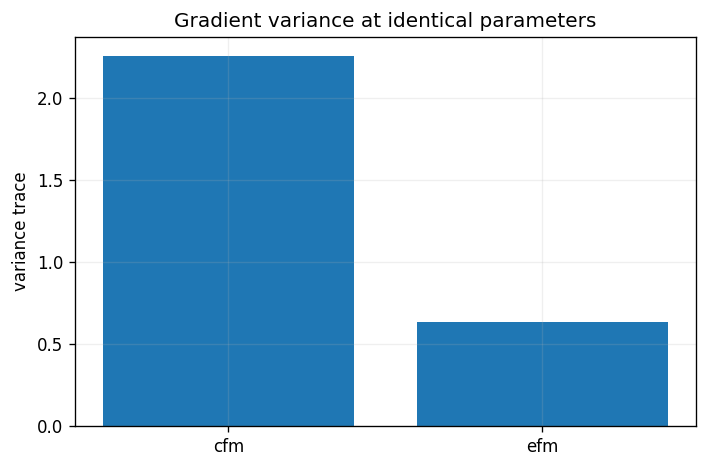

{'cfm': {'gradient_variance_trace': 2.2588229179382324, 'mean_gradient_norm': 1.629399299621582}, 'efm': {'gradient_variance_trace': 0.6364568471908569, 'mean_gradient_norm': 1.0706379413604736}}


In [11]:
def gradient_variance(model,dataset,kind,repeats=40,batch=256,M=16):
    grads=[]
    for _ in range(repeats):
        x,t,y=make_training_batch(dataset,batch,kind,M); pred=model(x,t);loss=(pred-y).square().mean()
        model.zero_grad(set_to_none=True);loss.backward()
        grads.append(torch.cat([p.grad.flatten() for p in model.parameters()]).detach().cpu())
    g=torch.stack(grads);return (g-g.mean(0)).square().sum(1).mean().item(),g.norm(dim=1).mean().item()

J_results={}
for kind in ["cfm","efm"]:
    var,norm=gradient_variance(cfm_model,train_data,kind)
    J_results[kind]={"gradient_variance_trace":var,"mean_gradient_norm":norm}
fig,ax=plt.subplots(figsize=(6,4));keys=["cfm","efm"]
ax.bar(keys,[J_results[k]["gradient_variance_trace"] for k in keys]);ax.set(title="Gradient variance at identical parameters",ylabel="variance trace")
fig.tight_layout();fig.savefig(OUT/"09_gradient_variance.png",bbox_inches="tight");plt.show();print(J_results)


## 11. 小规模灰度数据实验

构造 8×8 的线条、斜线与十字合成图像。它们位于 64 维环境空间，但主要由形状、平移和像素噪声等少数因素控制。分别训练 CFM 与 EFM，再比较其对精确经验场的拟合、生成分布和训练集最近邻距离。


Training 8×8 grayscale CFM...


cfm width=128 step=1000 loss=0.3383


cfm width=128 step=2000 loss=0.3016
Training 8×8 grayscale EFM...


efm width=128 step=1000 loss=0.2688


efm width=128 step=2000 loss=0.2590


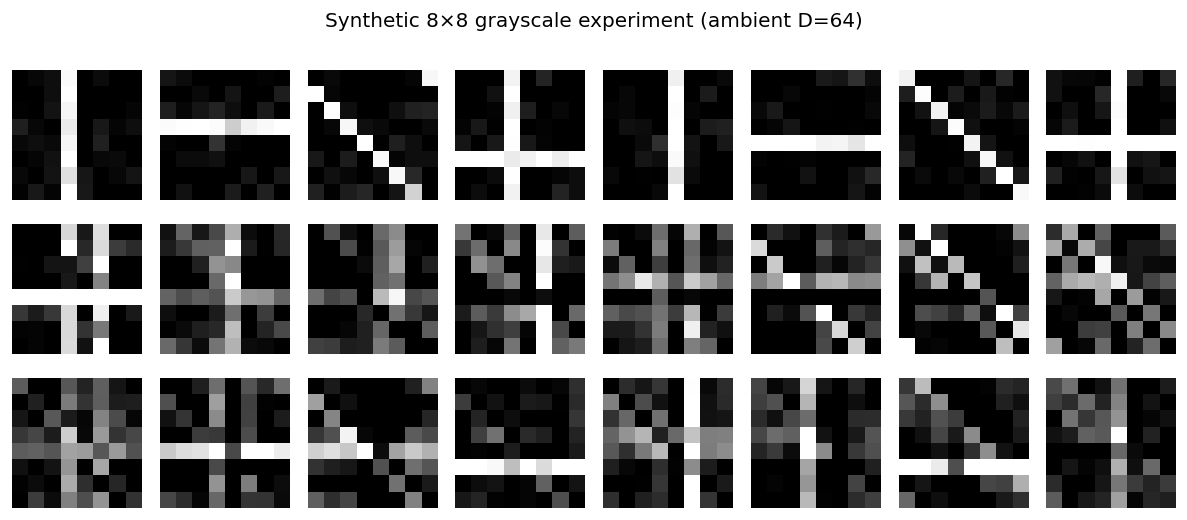

{
  "CFM": {
    "times": [
      0.05000000074505806,
      0.15000000596046448,
      0.30000001192092896,
      0.5,
      0.699999988079071,
      0.8500000238418579,
      0.949999988079071
    ],
    "field_mse": [
      0.16652724146842957,
      0.13525938987731934,
      0.09028515964746475,
      0.13804024457931519,
      0.22681355476379395,
      0.3538919985294342,
      0.822792649269104
    ],
    "swd": 0.08253875374794006,
    "nn_train": 2.447516918182373
  },
  "EFM": {
    "times": [
      0.05000000074505806,
      0.15000000596046448,
      0.30000001192092896,
      0.5,
      0.699999988079071,
      0.8500000238418579,
      0.949999988079071
    ],
    "field_mse": [
      0.1631026268005371,
      0.12769609689712524,
      0.08807027339935303,
      0.12558043003082275,
      0.21537092328071594,
      0.3638612926006317,
      0.8217558860778809
    ],
    "swd": 0.08770444989204407,
    "nn_train": 2.376903533935547
  }
}


In [12]:
def synthetic_digits(n=64,size=8):
    imgs=[]
    for i in range(n):
        a=torch.zeros(size,size); k=i%4; shift=(i//4)%3-1
        if k==0:a[:,(size//2+shift)%size]=1
        elif k==1:a[(size//2+shift)%size,:]=1
        elif k==2:
            j=torch.arange(size);a[j,(j+shift)%size]=1
        else:
            a[:,(size//2+shift)%size]=1;a[(size//2-shift)%size,:]=1
        a=(a+.08*torch.randn_like(a)).clamp(0,1);imgs.append(a)
    return torch.stack(imgs)

seed_all(50)
gray_train_img=synthetic_digits(64); gray_test_img=synthetic_digits(2048)
gray_train=gray_train_img.reshape(64,-1).to(DEVICE); gray_test=gray_test_img.reshape(2048,-1).to(DEVICE)
print("Training 8×8 grayscale CFM...")
gray_cfm,gray_cfm_hist=train_velocity(gray_train,"cfm",width=128,steps=2000,batch=256,seed=51)
print("Training 8×8 grayscale EFM...")
gray_efm,gray_efm_hist=train_velocity(gray_train,"efm",width=128,steps=2000,batch=256,M=16,seed=52)
gray_results={}
gray_results["CFM"],gray_cfm_samples=network_diagnostics(gray_cfm,gray_train,gray_test)
gray_results["EFM"],gray_efm_samples=network_diagnostics(gray_efm,gray_train,gray_test)

fig,axes=plt.subplots(3,8,figsize=(10,4.5))
sets=[gray_train[:8],gray_cfm_samples[:8],gray_efm_samples[:8]]
labels=["training","CFM generated","EFM generated"]
for row,(samples,label) in enumerate(zip(sets,labels)):
    for col,img in enumerate(samples):
        axes[row,col].imshow(img.reshape(8,8).detach().cpu().clamp(0,1),cmap="gray",vmin=0,vmax=1)
        axes[row,col].axis("off")
    axes[row,0].set_ylabel(label)
fig.suptitle("Synthetic 8×8 grayscale experiment (ambient D=64)")
fig.tight_layout();fig.savefig(OUT/"10_grayscale_generation.png",bbox_inches="tight");plt.show()
print(json.dumps(gray_results,indent=2))


## 12. 保存统一结果并形成结论

以下单元保存所有数值。运行后应从数据得出结论，不能把论文假设当成 toy 实验已经证明的事实。


In [13]:
results={"A_closed_form":A_metrics,"C_memorization":C_metrics,"F_efm_mc":F_results,
         "D_G_training":D_results,"E_hybrid":E_results,"I_capacity":I_results,"J_gradient":J_results,
         "grayscale_64d":gray_results}
(OUT/"metrics.json").write_text(json.dumps(results,indent=2),encoding="utf-8")

summary={
 "closed_form_score_error":A_metrics["score_relation_max_abs"],
 "exact_generated_to_train_nn":C_metrics["generated_to_train_nn"],
 "real_test_to_train_nn":C_metrics["test_to_train_nn"],
 "CFM_swd":D_results["CFM"]["swd"],"EFM_swd":D_results["EFM"]["swd"],
 "CFM_gradient_variance":J_results["cfm"]["gradient_variance_trace"],
 "EFM_gradient_variance":J_results["efm"]["gradient_variance_trace"],
}
print(json.dumps(summary,indent=2))
print("saved:",OUT/"metrics.json")


{
  "closed_form_score_error": 9.5367431640625e-07,
  "exact_generated_to_train_nn": 0.012386352755129337,
  "real_test_to_train_nn": 0.17973968386650085,
  "CFM_swd": 0.19203805923461914,
  "EFM_swd": 0.2920973300933838,
  "CFM_gradient_variance": 2.2588229179382324,
  "EFM_gradient_variance": 0.6364568471908569
}
saved: closed_form_fm_outputs/metrics.json


## 13. 实验覆盖表

| 实验 | 内容 | 对应部分 |
|---|---|---|
| A | 闭式速度、score、后验 Monte Carlo | 第 2 节 |
| B | Target 随机性与维度 | 第 3 节 |
| C | 精确经验流记忆训练集 | 第 4 节 |
| D | 二维及 64 维灰度数据上的网络拟合误差与泛化 | 第 6、11 节 |
| E | 正向与反向 Hybrid Flow | 第 7 节 |
| F | EFM 无偏性、方差、两个错误对照 | 第 5 节 |
| G | CFM 与 EFM 训练效果 | 第 6 节 |
| H | 环境维度与内在维度 | 第 8 节 |
| I | 网络容量与记忆 | 第 9 节 |
| J | Target 方差与梯度方差 | 第 10 节 |

精确经验场只对应有限训练集，因此其“最优”是经验风险意义下的最优。EFM 是否改善最终生成取决于候选数、网络和优化配置；无偏性与较低 Target 方差并不自动保证更低的生成误差。


## 14. 本次运行结论

1. **闭式公式实现正确。** 直接后验平均与 score 关系的最大绝对误差为 `9.54e-07`。
2. **精确经验流明确记忆训练集。** 生成样本到训练集最近邻的平均距离为 `0.0124`，而独立目标样本为 `0.1797`。
3. **高环境维度本身不是后验集中原因。** 固定内在维度 $r=4$ 时，$D=8,32,128$ 的熵曲线几乎重合；固定 $D=64$ 增大 $r$ 时，后验集中明显提前。
4. **EFM 正确候选构造降低 Target 方差。** CFM 方差为 `7.686`，EFM 在 $M=32$ 时为 `0.991`。全部均匀采样和直接算术平均并不满足相同的有限 $M$ 无偏性质。
5. **较低 Target/梯度方差不保证更低生成误差。** 二维实验中 CFM/EFM 的 SWD 为 `0.192` / `0.292`；梯度方差迹为 `2.259` / `0.636`。EFM 优化更稳定，但该 toy 预算下 SWD 没有改善。
6. **64 维灰度实验得到相同提醒。** CFM/EFM 的 SWD 为 `0.083` / `0.088`，两者接近，不能从方差下降直接推出生成质量上升。
7. **Hybrid Flow 显示晚期精确场主导记忆。** 只要轨迹末段切换到精确经验场，最近训练样本距离就下降到约 `0.02`；末段由网络控制时距离维持在约 `0.15`。

因此，实验支持论文的核心区分：Target 随机性不是泛化的必要来源；精确拟合有限样本的经验最优场反而导致记忆，而网络近似误差、数据内在结构和时间区间共同决定泛化。EFM 的无偏性与方差优势是估计性质，最终生成质量仍需单独验证。
